# Image Preprocessing Playground untuk Mata Kuliah Pengenalan Pola

**Penulis:** Tim Mahasiswa / Peneliti Pengenalan Pola  
**Tujuan Akademik:** Mengeksplorasi, membandingkan, dan memvisualisasikan berbagai teknik mendasar *image preprocessing* citra digital menggunakan Python dan Jupyter Notebook.  
**Fokus Studi:** Pemahaman konseptual, karakteristik matematis transformasi, dan inspeksi visual. Proyek ini **tidak** melatih model machine learning / neural network, tidak memprediksi ekspresi emosi, dan tidak menjadikan akurasi klasifikasi sebagai tolak ukur.

---

### Dataset Eksperimen
Dataset yang digunakan adalah citra wajah publik dari Kaggle:
[Facial Emotion Recognition Images Raw Dataset](https://www.kaggle.com/datasets/frmgtx/facial-emotion-recognition-images-raw-dataset)

*Catatan:* Citra wajah digunakan semata-mata sebagai objek eksperimen visual representasi pola citra nyata (tekstur kulit, gradien mata/mulut, pencahayaan). Jika dataset belum diunduh, sistem secara otomatis menyediakan citra demo sintetis terstruktur agar seluruh modul tetap dapat dijalankan dan dipelajari secara interaktif.

## 0. Persiapan Lingkungan dan Import Dependensi

In [55]:
# Memastikan modul lokal src dapat diakses
import sys
import importlib
from pathlib import Path
sys.path.append(str(Path.cwd()))

# Reload modul src jika sebelumnya sudah pernah dimuat di memori kernel Jupyter
for mod in list(sys.modules.keys()):
    if mod.startswith('src'):
        try:
            importlib.reload(sys.modules[mod])
        except Exception:
            pass

# Autoreload otomatis untuk menyinkronkan modifikasi modul .py ke notebook
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

import numpy as np
import matplotlib.pyplot as plt
import cv2

# Import fungsi publik dari setiap modul preprocessing
from src.dataloader import (
    load_image, get_image_list, get_image_metadata,
    create_synthetic_face, select_random_image,
    download_kaggle_dataset, load_experiment_image
)
from src.colorspaces import visualize_color_spaces
from src.geometrictransformations import visualize_geometric_transforms
from src.imagefiltering import visualize_filters
from src.histogramprocessing import visualize_histogram_processing
from src.imageenhancement import visualize_image_enhancement
from src.morphologicaloperations import visualize_morphological_operations
from src.noiseprocessing import visualize_noise_processing
from src.thresholding import visualize_thresholding
from src.segmentation import visualize_segmentation
from src.imagepyramids import visualize_image_pyramids
from src.numericalpreprocessing import visualize_numerical_preprocessing
from src.augmentation import visualize_augmentations

# Import fungsi publik dari modul Feature Extraction
from src.featureedge import visualize_edge_features
from src.featurekeypoint import visualize_keypoint_features
from src.featuretexture import visualize_texture_features
from src.featurecolor import visualize_color_features
from src.featureshape import visualize_shape_features

# Set inline plotting untuk visualisasi notebook
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Semua modul dan dependensi berhasil dimuat!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Semua modul dan dependensi berhasil dimuat!


## 0.1 Konfigurasi Path dan Pemuatan Gambar Eksperimen

Kita menyediakan variabel boolean `user_synthetic_data = False` untuk memilih sumber citra eksperimen:
- **`user_synthetic_data = True`**: Menggunakan citra uji sintetis (`create_synthetic_face()`) beresolusi 256x256 secara instan tanpa perlu unduhan.
- **`user_synthetic_data = False`**: Menggunakan citra nyata dari dataset Kaggle (`frmgtx/facial-emotion-recognition-images-raw-dataset`). Jika direktori `data/` masih kosong, fungsi `download_kaggle_dataset()` secara otomatis mengunduh dataset dan mengekstrak file zip ke direktori `data/` sehingga citra dapat langsung diakses.

Ditemukan 2222 citra pada dataset lokal.
Menggunakan citra: data\emotion-recognition-raw\Anger\Anger_199.jpg

Metadata Citra Eksperimen:
 - shape: (256, 256, 3)
 - height: 256
 - width: 256
 - channels: 3
 - dtype: uint8
 - min_intensity: 0.0
 - max_intensity: 253.0
 - mean_intensity: 127.98987325032552
 - std_intensity: 82.99087188769066


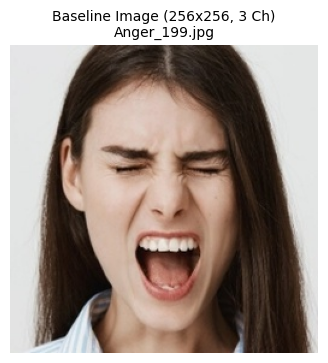

In [56]:
# Skema pemilihan data eksperimen:
# True  -> Gunakan data wajah sintetis (create_synthetic_face)
# False -> Gunakan data Kaggle yang diunduh & diekstrak ke folder data/
user_synthetic_data = False
use_synthetic_data = user_synthetic_data  # Alias fleksibel

if user_synthetic_data:
    print("Mode: Menggunakan citra uji sintetis (create_synthetic_face)...")
    sample_image = create_synthetic_face(height=256, width=256, seed=42)
    img_display_name = "synthetic_face_256x256.png"
else:
    # Periksa direktori data/, jika masih kosong, lakukan download dari Kaggle & ekstrak zip
    dataset_images = get_image_list("data/")
    if len(dataset_images) == 0:
        print("Direktori data/ masih kosong. Mengunduh dataset dari Kaggle dan mengekstrak file zip...")
        download_kaggle_dataset("data/")
        dataset_images = get_image_list("data/")

    if len(dataset_images) > 0:
        print(f"Ditemukan {len(dataset_images)} citra pada dataset lokal.")
        sample_image, img_path = select_random_image("data/", seed=42)
        print(f"Menggunakan citra: {img_path}")
        img_display_name = Path(img_path).name
    else:
        print("Peringatan: Gagal memuat citra dari Kaggle. Beralih ke citra uji sintetis...")
        sample_image = create_synthetic_face(height=256, width=256, seed=42)
        img_display_name = "synthetic_face_256x256 (fallback)"

# Inspeksi metadata gambar dasar
meta = get_image_metadata(sample_image)
print("\nMetadata Citra Eksperimen:")
for k, v in meta.items():
    print(f" - {k}: {v}")

# Tampilkan baseline citra
plt.figure(figsize=(4, 4))
plt.imshow(sample_image)
plt.title(f"Baseline Image ({meta['width']}x{meta['height']}, {meta['channels']} Ch)\n{img_display_name}", fontsize=10)
plt.axis("off")
plt.show()


---
## Section 1: Representasi dan Ruang Warna (Color Spaces)

### Konsep Dasar & Definisi
Ruang warna (*color space*) adalah model matematika yang mendeskripsikan cara warna diwakili sebagai deretan angka (*tuple*). Ruang warna yang berbeda merefleksikan kebutuhan sensorik dan algoritma yang berbeda:
- **RGB:** Model aditif primer (Red, Green, Blue) yang bersesuaian langsung dengan sensor kamera dan layar monitor.
- **BGR:** Perubahan urutan kanal internal pada OpenCV (Blue, Green, Red). Ini bukan ruang warna baru secara fisika, melainkan format penyimpanan *byte ordering* memori.
- **Grayscale:** Proyeksi intensitas luminans monokromatik (biasanya $Y = 0.299R + 0.587G + 0.114B$) untuk mereduksi kompleksitas komputasi saat informasi kromatik tidak esensial.
- **HSV / HLS:** Memisahkan informasi kromatis murni (*Hue* dan *Saturation*) dari komponen intensitas/kecerahan (*Value* atau *Lightness*). Sangat tahan terhadap variasi pencahayaan pada segmentasi warna kulit wajah.
- **CIE LAB:** Ruang warna seragam secara perseptual (*perceptually uniform*). Kanal $L$ memuat luminans, sedangkan $a$ (sumbu hijau-merah) dan $b$ (sumbu biru-kuning) memisahkan krominans.
- **YCrCb & YUV:** Sering digunakan pada transmisi video digital dan kompresi citra (seperti JPEG). $Y$ adalah luminans, sedangkan $Cr$/$Cb$ dan $U$/$V$ adalah *chrominance difference*.
- **CMYK:** Model subtraktif (Cyan, Magenta, Yellow, Key/Black) yang menjadi standar industri cetak fisik.

### Keterbatasan
Menampilkan kanal non-RGB (seperti HSV atau LAB) secara langsung sebagai citra RGB akan menghasilkan visualisasi artifisial yang menyesatkan karena interpretasi rentang nilai tiap kanal berbeda (misal Hue OpenCV bernilai 0–179).

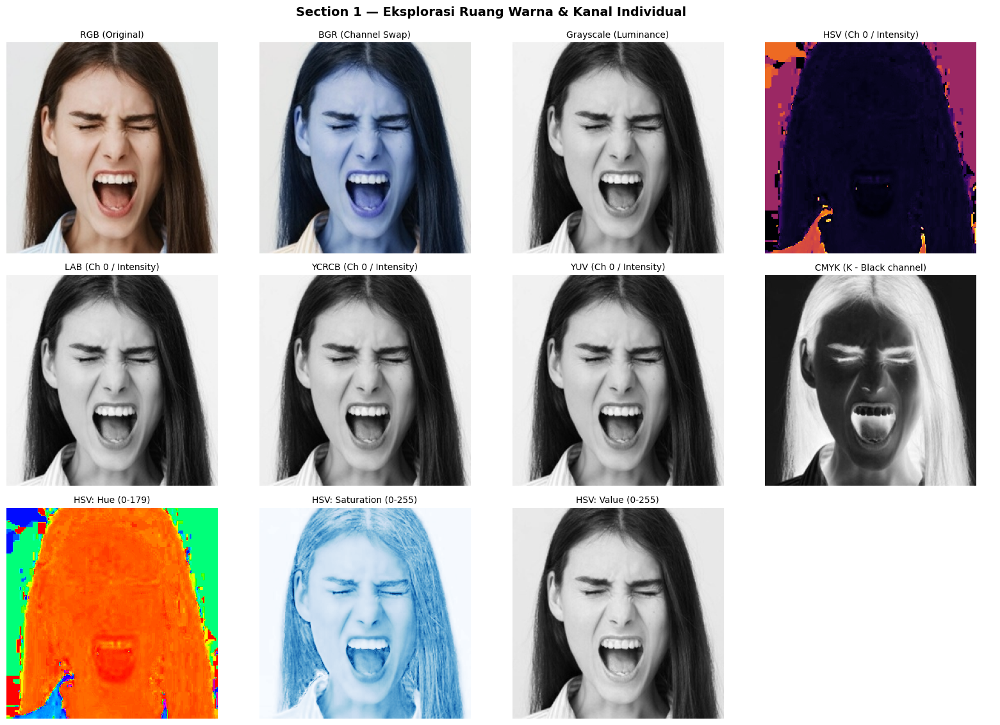

In [57]:
# Eksekusi visualisasi ruang warna dan inspeksi kanal HSV
color_results = visualize_color_spaces(
    sample_image,
    spaces=["rgb", "bgr", "gray", "hsv", "lab", "ycrcb", "yuv", "cmyk"],
    show_channels=True,
    channel_space="hsv",
    ncols=4,
    show=True
)

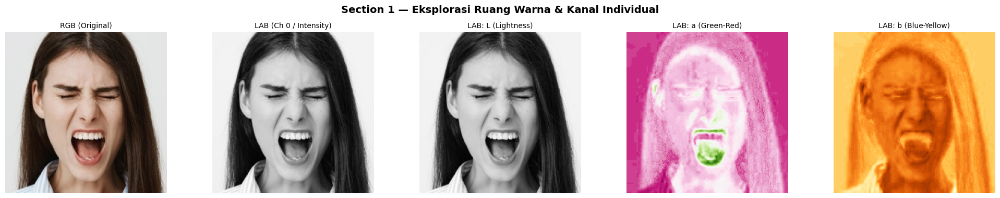

In [58]:
# Eksperimen Alternatif: Tampilkan kanal individual dari ruang warna CIE LAB
_ = visualize_color_spaces(
    sample_image,
    spaces=["rgb", "lab"],
    show_channels=True,
    channel_space="lab",
    ncols=5,
    show=True
)

---
## Section 2: Transformasi Geometris (Geometric Transformations)

### Konsep Dasar & Definisi
Transformasi geometris mengubah hubungan spasial antarpiksel dalam sistem koordinat citra tanpa mengubah nilai intensitas warna intrinsik dari objek:
- **Crop:** Memotong ROI (*Region of Interest*) spesifik pada koordinat $(y_{min}:y_{max}, x_{min}:x_{max})$.
- **Resize & Scaling:** Mengubah dimensi spasial dengan estimasi nilai piksel baru melalui interpolasi linier/kubik.
- **Rotation:** Memutar citra sebesar sudut $\theta$ derajat mengitari titik poros $(x_c, y_c)$.
- **Translation (Shift):** Menggeser posisi citra sebesar $(t_x, t_y)$ piksel.
- **Flip:** Pencerminan horizontal (sumbu vertikal) atau vertikal (sumbu horizontal).
- **Shear:** Kemiringan koordinat sejajar sumbu horizontal/vertikal.
- **Affine Transformation:** Transformasi yang mempertahankan garis paralel (ditentukan oleh pemetaan 3 titik sudut).
- **Perspective Transformation (Homography):** Transformasi proyektif planar yang memodelkan perubahan sudut pandang kamera (ditentukan oleh pemetaan 4 titik sudut).

### Parameter Penting & Penanganan Border
Transformasi rotasi, geser, dan perspektif menghasilkan area kosong di luar canvas asli. Kita menangani area ini menggunakan `borderMode` (seperti `BORDER_CONSTANT` atau `BORDER_REFLECT`).

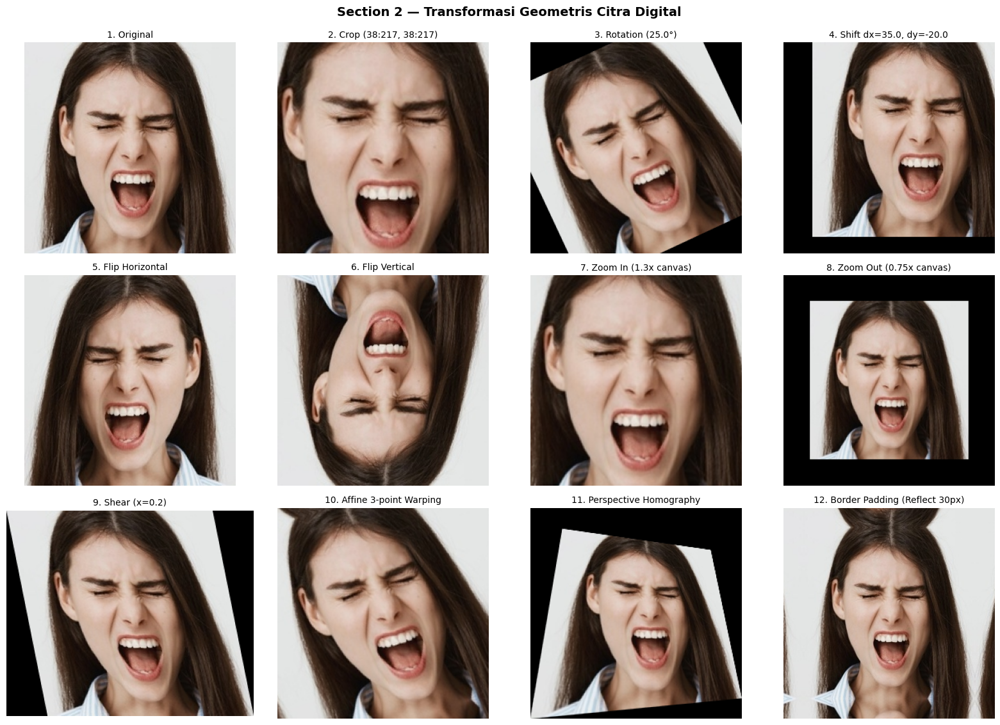

In [59]:
# Eksekusi visualisasi transformasi geometris lengkap
h, w = sample_image.shape[:2]
geom_results = visualize_geometric_transforms(
    sample_image,
    crop_coords=(int(h * 0.15), int(h * 0.85), int(w * 0.15), int(w * 0.85)),
    rotation_angle=25.0,
    shift=(35.0, -20.0),
    zoom_in_factor=1.3,
    zoom_out_factor=0.75,
    shear_factor=0.2,
    ncols=4,
    show=True
)

---
## Section 3: Filtering dan Konvolusi Citra (Filtering & Convolution)

### Konsep Dasar & Definisi
Filtering spasial beroperasi dengan menggeser matriks bobot (*kernel* / *mask*) berukuran ganjil $(2k+1) \times (2k+1)$ ke seluruh piksel citra melalui operasi konvolusi 2D:
$$g(x, y) = \sum_{s} \sum_{t} w(s, t) f(x+s, y+t)$$

- **Smoothing / Blur (Low-Pass Filter):**
  - *Box Blur:* Rata-rata sederhana piksel tetangga. Cepat namun dapat menghasilkan artefak garis kotak.
  - *Gaussian Blur:* Bobot terdistribusi normal lonceng berdasarkan parameter $\sigma$. Mengaburkan tekstur dengan transisi lembut tanpa artefak arah.
  - *Median Filter:* Filter non-linier yang mengganti piksel dengan nilai median lokal. Sangat efektif membasmi *salt-and-pepper noise* tanpa mengaburkan tepi tajam.
  - *Bilateral Filter:* Menggabungkan bobot jarak spasial domain $(\sigma_{space})$ dan kedekatan intensitas rentang $(\sigma_{color})$. Menghaluskan area homogen sekaligus menjaga tepi objek tetap tajam (*edge-preserving*).
- **Sharpening (High-Pass Filter):** Menekankan frekuensi spasial tinggi dengan menambahkan turunan kedua laplacian ke citra asli.
- **Deteksi Tepi:**
  - *Sobel:* Mengestimasi gradien turunan pertama arah horizontal ($G_x$) dan vertikal ($G_y$).
  - *Laplacian:* Mengukur turunan kedua isotropik untuk menemukan *zero-crossing* perubahan intensitas.
  - *Canny:* Algoritma multi-tahap (Gaussian blur, kalkulasi gradien Sobel, *Non-Maximum Suppression*, dan *Hysteresis Thresholding*) untuk menghasilkan garis tepi setebal 1 piksel.

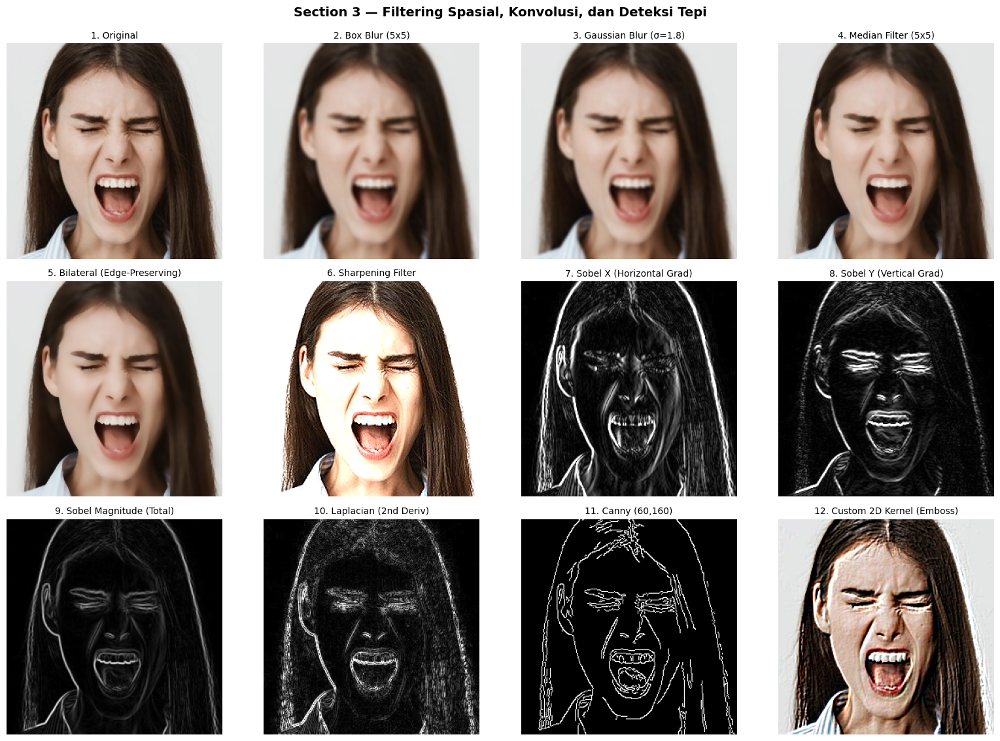

In [60]:
# Eksekusi visualisasi filtering spasial dan deteksi tepi
filter_results = visualize_filters(
    sample_image,
    kernel_size=5,
    gaussian_sigma=1.8,
    canny_thresholds=(60, 160),
    ncols=4,
    show=True
)

---
## Section 4: Histogram dan Distribusi Intensitas (Histogram Processing)

### Konsep Dasar & Definisi
Histogram citra adalah diagram frekuensi yang menggambarkan distribusi jumlah piksel untuk setiap tingkat intensitas warna (0–255):
- **Global Histogram Equalization:** Meratakan fungsi distribusi kumulatif (CDF) intensitas ke seluruh rentang dinamis. Kelemahannya: dapat menyebabkan kontras berlebihan (*over-exposure*) atau memperkuat noise latar belakang.
- **CLAHE (Contrast Limited Adaptive Histogram Equalization):** Menghitung equalization secara lokal pada blok *tile* kecil (misal $8 \times 8$) dan membatasi puncak kontras (*clip limit*). Untuk citra RGB, CLAHE diterapkan secara benar pada **kanal luminans (L dari LAB atau Y dari YCrCb)** agar tidak merusak keseimbangan warna alami wajah.
- **Contrast Stretching:** Meregangkan intensitas piksel secara linier antara batas persentil bawah (misal 2%) dan persentil atas (98%) untuk menghilangkan rentang kosong tanpa terdistorsi *outlier*.

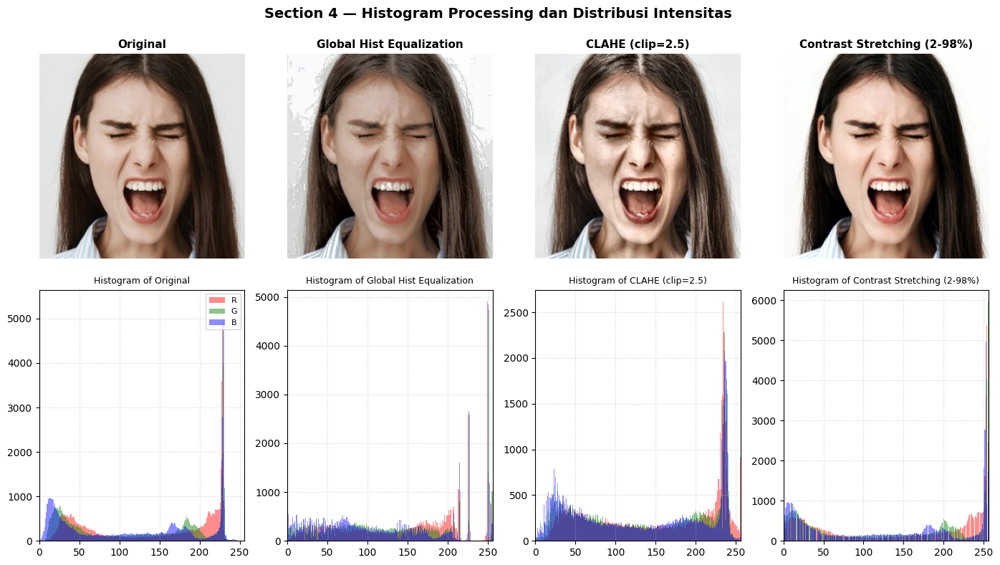

In [61]:
# Eksekusi visualisasi histogram processing sebelum dan sesudah
hist_results = visualize_histogram_processing(
    sample_image,
    clahe_clip_limit=2.5,
    figsize=(14, 8),
    show=True
)

---
## Section 5: Image Enhancement (Peningkatan Kualitas Citra)

### Konsep Dasar & Definisi
Enhancement bertujuan meningkatkan visibilitas informasi tertentu untuk konsumsi visual manusia atau tahap segmentasi pola berikutnya:
- **Brightness Adjustment:** Menggeser histogram secara horizontal melalui penambahan konstanta $I_{out} = \text{clip}(I_{in} + \beta, 0, 255)$.
- **Contrast Adjustment:** Meregangkan atau mempersempit deviasi intensitas dari nilai tengah $I_{out} = \text{clip}(\alpha(I_{in} - 127.5) + 127.5, 0, 255)$.
- **Gamma Correction (Power-Law):** $I_{out} = c \cdot I_{in}^\gamma$. Nilai $\gamma < 1$ mencerahkan area gelap (*shadows*) tanpa merusak area terang, sedangkan $\gamma > 1$ menggelapkan area terang.
- **Unsharp Masking:** Mempertajam transisi tepi dengan mengekstraksi komponen detail frekuensi tinggi.

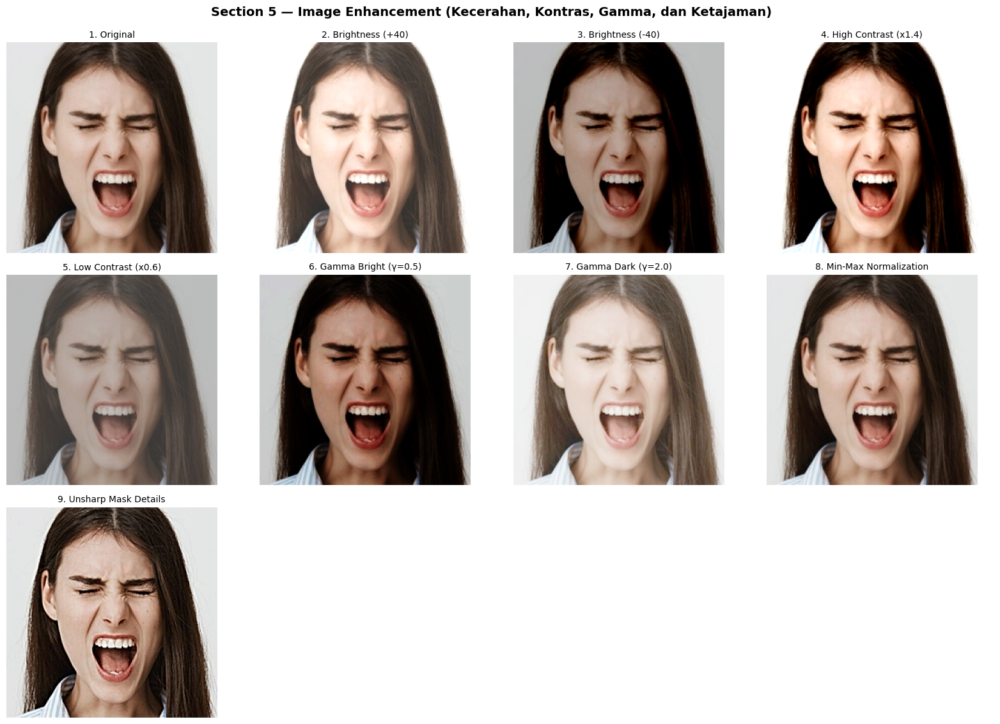

In [62]:
# Eksekusi visualisasi image enhancement
enh_results = visualize_image_enhancement(
    sample_image,
    brightness_offset=40,
    contrast_factor=1.4,
    gamma_values=(0.5, 2.0),
    ncols=4,
    show=True
)

---
## Section 6: Operasi Morfologi (Morphological Operations)

### Konsep Dasar & Definisi
Morfologi matematika memproses bentuk geometris objek berdasarkan *structuring element* (SE / kernel):
- **Erosion ($A \ominus B$):** Mengikis batas luar objek foreground biner; menghilangkan pulau piksel kecil yang terisolasi.
- **Dilation ($A \oplus B$):** Memperluas area objek foreground; menyambungkan garis terputus dan menutup celah kecil.
- **Opening ($A \circ B = (A \ominus B) \oplus B$):** Erosi diikuti Dilasi; membasmi tonjolan tipis dan noise kecil tanpa mengubah ukuran total objek.
- **Closing ($A \bullet B = (A \oplus B) \ominus B$):** Dilasi diikuti Erosi; menutup lubang-lubang kecil di dalam objek dan menjembatani celah sempit.
- **Morphological Gradient ($Dilation - Erosion$):** Menghasilkan garis tepi kontur objek.
- **Top-Hat ($Input - Opening$):** Mengisolasi elemen terang yang berukuran lebih kecil dari SE.
- **Black-Hat ($Closing - Input$):** Mengisolasi elemen gelap yang berukuran lebih kecil dari SE.

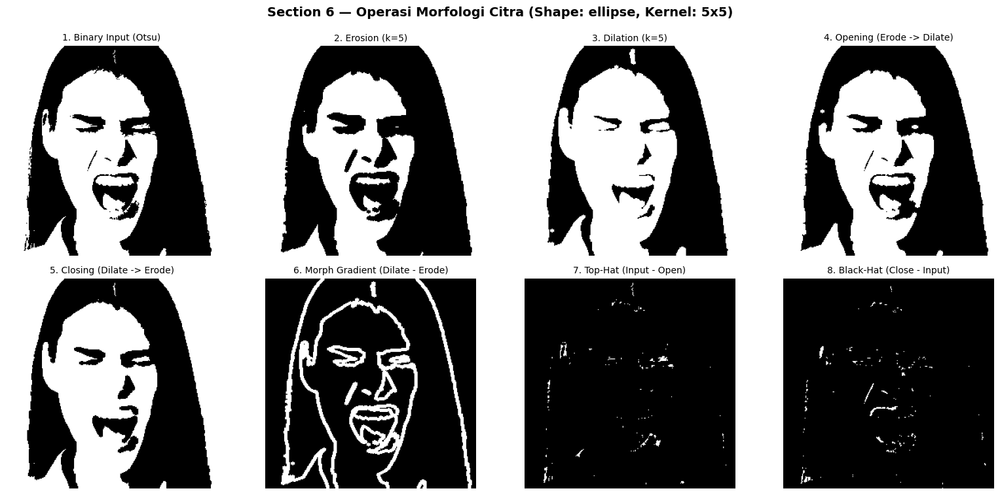

In [63]:
# Eksekusi visualisasi operasi morfologi pada citra biner (Otsu)
morph_results = visualize_morphological_operations(
    sample_image,
    kernel_size=5,
    kernel_shape="ellipse",
    iterations=1,
    use_binary=True,
    ncols=4,
    show=True
)

---
## Section 7: Noise dan Denoising (Noise Processing)

### Konsep Dasar & Evaluasi Ground Truth
Noise adalah variasi acak yang tidak diinginkan pada intensitas atau warna citra akibat keterbatasan sensor atau interferensi transmisi:
- **Gaussian Noise:** Noise aditif dengan distribusi normal nol pada setiap piksel.
- **Salt-and-Pepper Noise:** Gangguan impuls berupa titik hitam (pepper: 0) dan titik putih (salt: 255) yang tersebar acak.
- **Speckle Noise:** Noise multiplikatif $I_{noisy} = I + I \times \eta$.

Kinerja filter dievaluasi secara obyektif terhadap citra asli (*ground truth*) menggunakan metrik kuantitatif:
- **MSE (Mean Squared Error):** $\text{MSE} = \frac{1}{MN}\sum (I_{orig} - I_{test})^2$ (semakin rendah semakin baik).
- **PSNR (Peak Signal-to-Noise Ratio):** $20 \log_{10}\left(\frac{255}{\sqrt{\text{MSE}}}\right)$ dalam dB (semakin tinggi semakin mendekati kualitas citra asli).

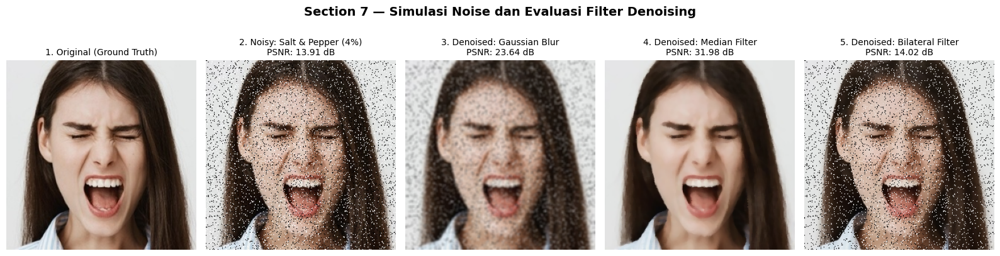

In [64]:
# Eksekusi uji Salt-and-Pepper noise dan evaluasi ketiga filter denoising
noise_sp_results = visualize_noise_processing(
    sample_image,
    noise_type="salt_and_pepper",
    noise_intensity=0.04,
    seed=42,
    show=True
)

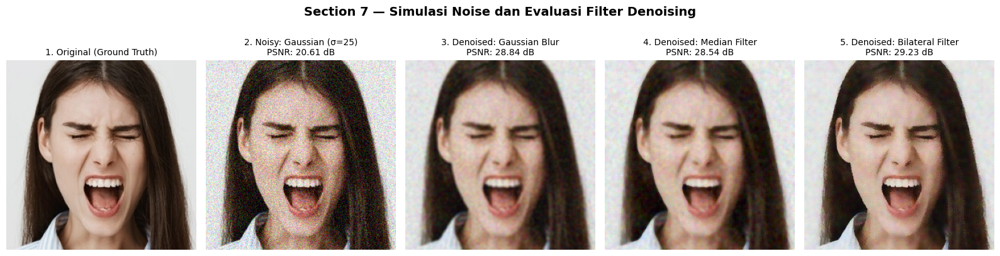

In [65]:
# Eksperimen Alternatif: Uji Gaussian Noise (sigma=25)
noise_gauss_results = visualize_noise_processing(
    sample_image,
    noise_type="gaussian",
    noise_intensity=0.10,
    seed=42,
    show=True
)

---
## Section 8: Thresholding dan Binarisasi (Thresholding & Binarization)

### Konsep Dasar & Definisi
Thresholding mengonversi citra bertingkat keabuan (*grayscale*) menjadi citra biner (hitam-putih) untuk memisahkan objek latar depan (*foreground*) dari latar belakang:
- **Global Fixed Thresholding:** Membandingkan seluruh piksel dengan nilai ambang tunggal konstan $T$.
- **Otsu's Thresholding:** Menghitung nilai ambang optimal secara otomatis dengan memaksimalkan varians antarkelas (*between-class variance*) dari histogram bimodal.
- **Adaptive Thresholding (Lokal):** Menghitung nilai ambang independen untuk setiap piksel berdasarkan rata-rata (*Mean*) atau bobot Gauss (*Gaussian*) di lingkungan tetangga ($N \times N$). Sangat tahan terhadap gradien iluminasi tidak merata pada citra wajah.

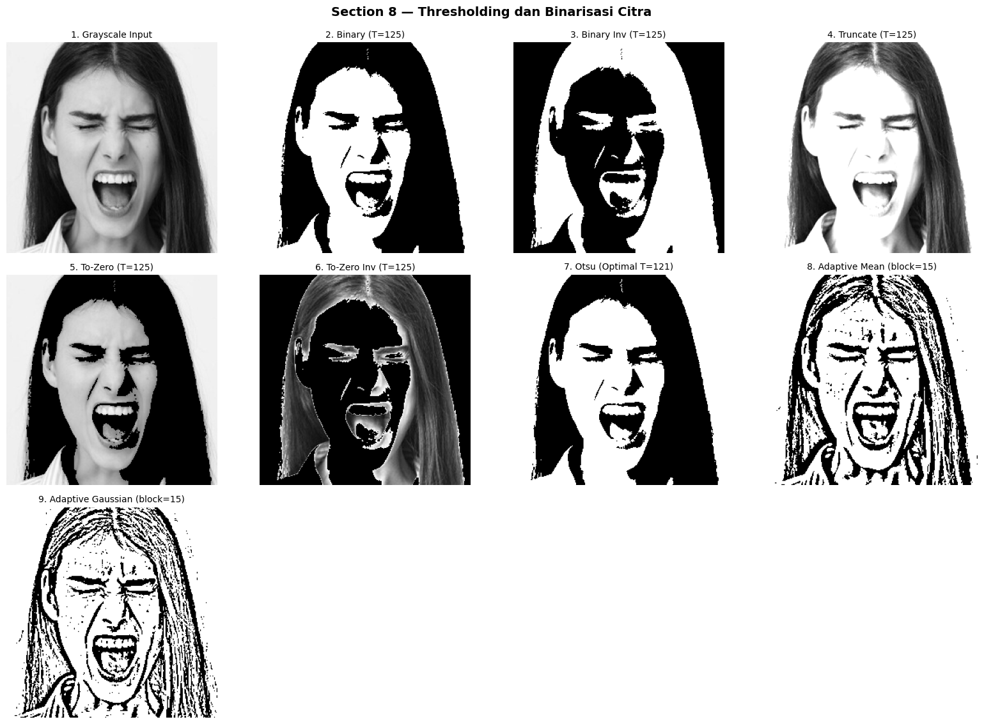

In [66]:
# Eksekusi visualisasi perbandingan metode thresholding
thresh_results = visualize_thresholding(
    sample_image,
    threshold=125,
    block_size=15,
    C=3,
    ncols=4,
    show=True
)

---
## Section 9: Segmentasi Citra Eksploratif (Image Segmentation)

### Konsep Dasar & Definisi
Segmentasi membagi citra ke dalam beberapa region homogen yang memiliki makna visual serupa:
- **Threshold Masking:** Memotong area objek tertentu berdasarkan interval intensitas biner.
- **K-Means Color Clustering:** Mengelompokkan vektor piksel $(R, G, B)$ ke dalam $K$ kluster warna dominan tanpa memperhatikan kedekatan spasial.
- **Contour Extraction:** Melacak kurva kontur batas luar objek dari citra biner.
- **Watershed Segmentation:** Menginterpretasikan intensitas citra sebagai permukaan topografi dan mensimulasikan genangan air dari titik-titik penanda (*markers*) lokal untuk memisahkan region yang bersentuhan.

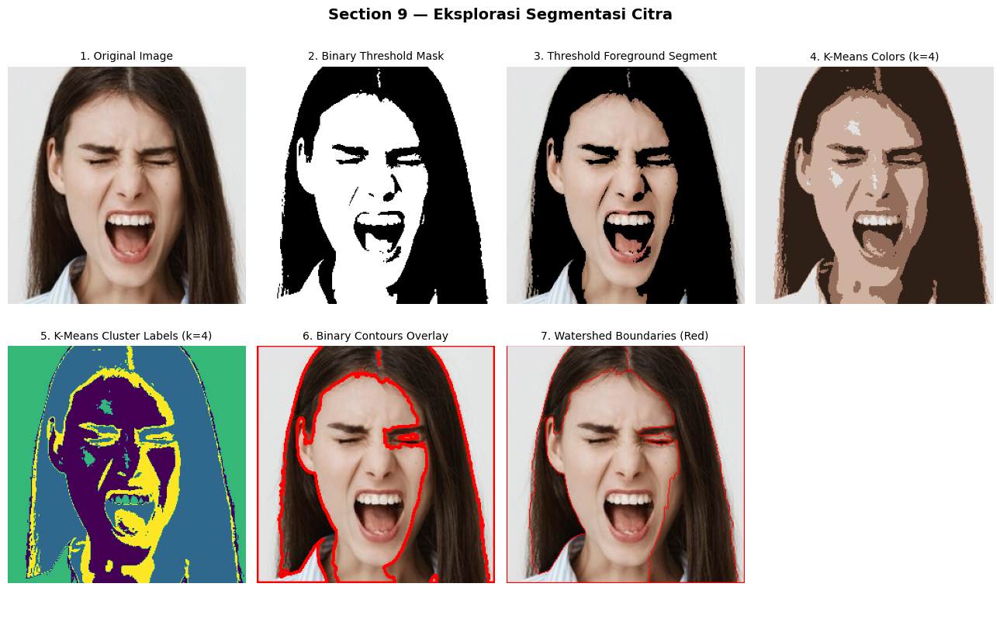

In [67]:
# Eksekusi visualisasi segmentasi citra
seg_results = visualize_segmentation(
    sample_image,
    n_clusters=4,
    seed=42,
    ncols=4,
    show=True
)

---
## Section 10: Multiresolusi dan Piramida Citra (Image Pyramids)

### Konsep Dasar & Definisi
Representasi multiresolusi memungkinkan analisis pola citra pada berbagai tingkat skala spasial secara efisien:
- **Gaussian Pyramid:** Dibangun dengan menerapkan Gaussian smoothing lalu downsampling sebesar faktor 2 secara bertingkat. Mengisolasi struktur skala global.
- **Laplacian Pyramid:** Menyimpan selisih antara level Gaussian dan ekspansi *upsampling* level di atasnya. Mengisolasi detail pita frekuensi tinggi (*band-pass*).
- **Metode Interpolasi:**
  - *Nearest Neighbor:* Tercepat namun menghasilkan efek *blocky/pixelated*.
  - *Bilinear:* Rata-rata terbobot 4 tetangga terdekat; transisi halus.
  - *Bicubic:* Memperhitungkan 16 piksel tetangga dengan kurva kubik; detail lebih terjaga.
  - *Lanczos:* Menggunakan fungsi sinc ter-window; ketajaman tepi maksimal namun lebih berat secara komputasi.

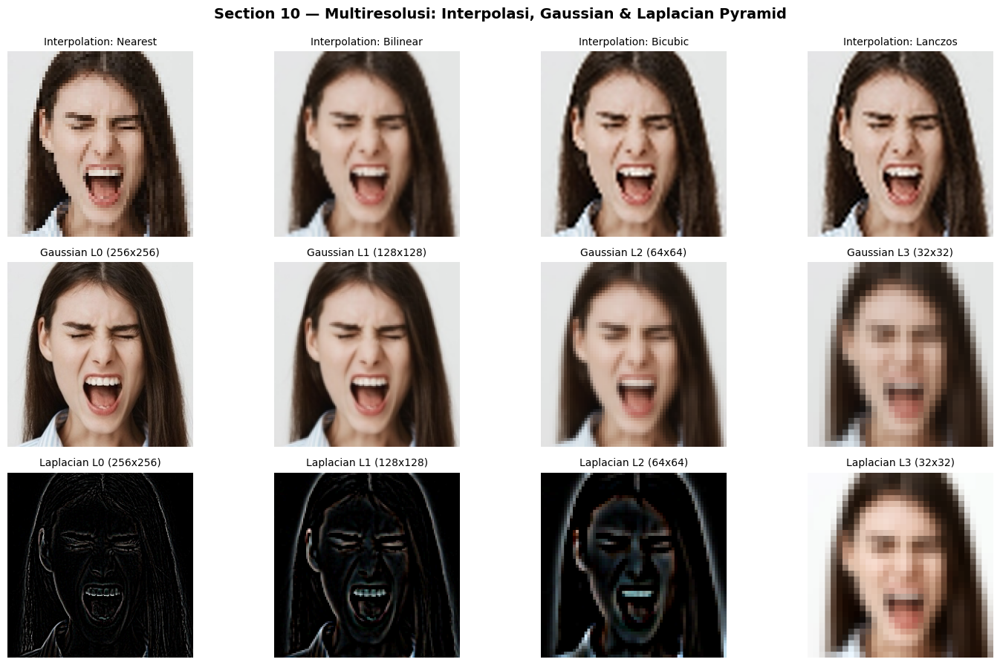

In [68]:
# Eksekusi perbandingan interpolasi dan visualisasi piramida
pyr_results = visualize_image_pyramids(
    sample_image,
    levels=4,
    scale_factor=0.25,
    ncols=4,
    show=True
)

---
## Section 11: Normalisasi dan Representasi Numerik (Numerical Preprocessing)

### Konsep Dasar & Karakteristik Statistik
Model komputasi dan algoritma pengenalan pola umumnya membutuhkan input array numerik floating point yang terstandardisasi:
- **uint8 ke float32:** Menghindari *saturation* dan *integer overflow/underflow* saat operasi matematika.
- **Normalisasi Min-Max $[0.0, 1.0]$:** Mengubah skala data secara proporsional $x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$.
- **Normalisasi Simetris $[-1.0, 1.0]$:** Standar input populer untuk fungsi aktivasi tanh / generator neural network.
- **Standardisasi Z-Score (Zero-Mean, Unit-Variance):** $z = \frac{x - \mu}{\sigma}$. Mengeliminasi bias rata-rata pencahayaan umum citra.

*Catatan:* Transformasi ini mengubah representasi nilai numerik pada array, bukan selalu memberikan perubahan visual estetika langsung.

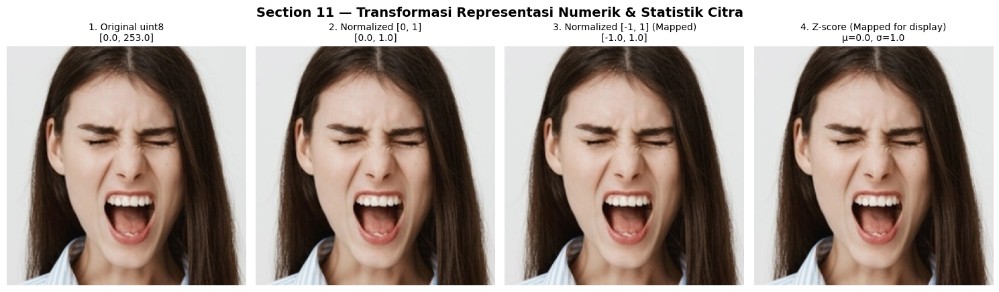


Tabel Ringkasan Statistik Numerik:
Original (uint8)         | Shape: (256, 256, 3) | Dtype: uint8   | Min:    0.000 | Max:  253.000 | Mean:  127.990 | Std:   82.991
Normalized [0, 1]        | Shape: (256, 256, 3) | Dtype: float32 | Min:    0.000 | Max:    1.000 | Mean:    0.506 | Std:    0.328
Normalized [-1, 1]       | Shape: (256, 256, 3) | Dtype: float32 | Min:   -1.000 | Max:    1.000 | Mean:    0.012 | Std:    0.656
Standardized Z-Score     | Shape: (256, 256, 3) | Dtype: float32 | Min:   -1.542 | Max:    1.506 | Mean:    0.000 | Std:    1.000


In [69]:
# Eksekusi inspeksi representasi numerik
num_results = visualize_numerical_preprocessing(
    sample_image,
    show=True
)

# Cetak tabel ringkasan statistik
print("\nTabel Ringkasan Statistik Numerik:")
for label, stat in num_results["stats"].items():
    print(f"{label:24s} | Shape: {str(stat['shape']):12s} | Dtype: {stat['dtype']:7s} | Min: {stat['min']:8.3f} | Max: {stat['max']:8.3f} | Mean: {stat['mean']:8.3f} | Std: {stat['std']:8.3f}")

---
## Section 12: Augmentasi Citra dan Eksperimen Gabungan (Data Augmentation)

### Konsep Dasar & Reproducibility
Augmentasi data citra memperkenalkan variabilitas sintetis yang realistis (rotasi kecil, variasi pencahayaan, pergeseran sudut kamera) untuk meningkatkan invariansi spasial algoritma pengenalan pola:
- Transformasi dibatasi pada rentang wajar (misal rotasi $\pm 15^\circ$, translasi $\le 8\%$) agar fitur pola wajah tidak terdistorsi menjadi tidak wajar.
- Seluruh variasi acak dikendalikan menggunakan *random seed* NumPy sehingga hasil eksperimen selalu dapat direproduksi ulang (*fully reproducible*).

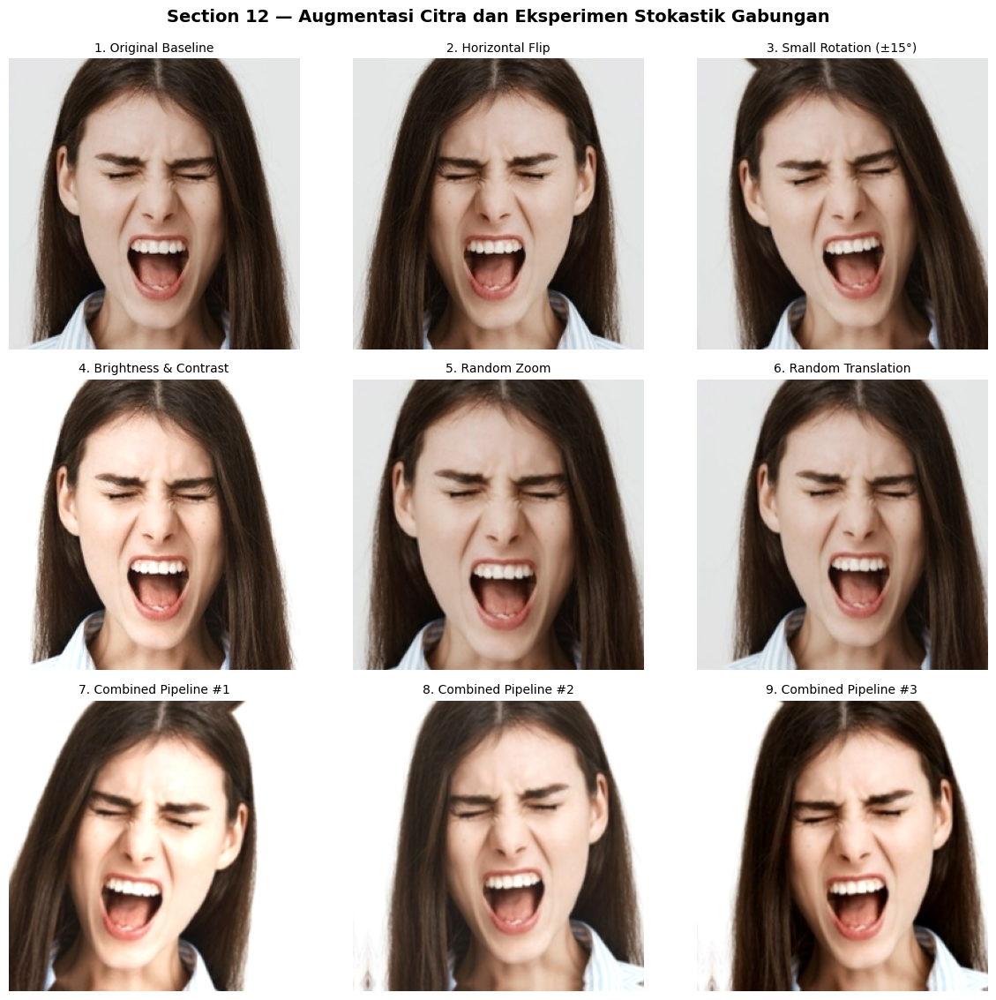

In [70]:
# Eksekusi visualisasi variasi augmentasi individual dan pipeline kombinasi
aug_results = visualize_augmentations(
    sample_image,
    n_samples=3,
    seed=42,
    ncols=3,
    show=True
)

---
# Feature Extraction Playground untuk Mata Kuliah Pengenalan Pola

Selamat datang di bagian kedua eksperimen: **Feature Extraction (Ekstraksi Fitur)**. Pada bagian ini, kita mengeksplorasi representasi citra tingkat lanjut yang mentransformasikan piksel-piksel mentah menjadi **deskriptor kuantitatif dan bermakna** (*feature vectors*) untuk sistem pengenalan pola.

Seluruh ekstraksi fitur di bawah ini memanfaatkan kapabilitas pra-pengolahan citra (*preprocessing*) yang telah dibangun pada Bagian 1, dan dikelompokkan ke dalam **5 karakteristik utama**:
1. **Edge Detection:** Gradien spasial dan detektor diskontinuitas intensitas (Sobel, Prewitt, Scharr, LoG, Canny).
2. **Corner & Keypoint:** Titik-titik jangkar dan fitur lokal invarian (Harris, Shi-Tomasi, FAST, SIFT, ORB).
3. **Tekstur (Texture):** Pola mikro dan distribusi statistik ketetanggaan piksel (GLCM Haralick, LBP, Gabor Filter Bank).
4. **Warna (Color):** Momen statistik kromatik dan distribusi spektrum warna (Color Moments, Histograms 1D/2D, K-Means Dominant Colors).
5. **Shape & Geometry:** Sifat geometris objek biner dan deskripsi bentuk (Kontur, 7 Hu Invariant Moments, Hough Transform, HOG).

---
## Section 13: Edge Detection & Spatial Gradients

### Konsep Dasar & Formulasi Matematis
Deteksi tepi mengidentifikasi batas-batas objek dengan mendeteksi perubahan tajam (*diskontinuitas*) pada fungsi intensitas citra $f(x, y)$:
- **Sobel Operator:** Mengestimasi turunan parsial orde pertama menggunakan kernel berbobot $3 \times 3$:
  $$G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix} * f, \quad G_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix} * f$$
  Magnitudo gradien: $|G| = \sqrt{G_x^2 + G_y^2}$ dan arah orientasi: $\theta = \arctan(G_y / G_x)$.
- **Prewitt Operator:** Mirip dengan Sobel namun menggunakan bobot seragam ($1, 1, 1$), memberikan respons yang lebih sensitif terhadap noise.
- **Scharr Operator:** Dirancang untuk meminimalkan error ketidaksimetrisan rotasi pada kernel $3 \times 3$ menggunakan bobot $(-3, 0, 3)$ dan $(-10, 0, 10)$.
- **Laplacian of Gaussian (LoG):** Menghitung turunan orde kedua $\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$ setelah penghalusan Gaussian, mencari titik perlintasan nol (*zero-crossing*).
- **Canny Edge Detector:** Algoritma optimal multi-tahap (Gaussian Blur $\rightarrow$ Gradient Calculation $\rightarrow$ Non-Maximum Suppression $\rightarrow$ Hysteresis Double Thresholding).

### Kaitan dengan Preprocessing Part 1
Diferensiasi numerik sangat rentan terhadap amplifikasi noise frekuensi tinggi. Oleh karena itu, teknik **Gaussian / Bilateral Smoothing** dari Section 3 & 7 diaplikasikan sebagai langkah awal wajib sebelum deteksi tepi.

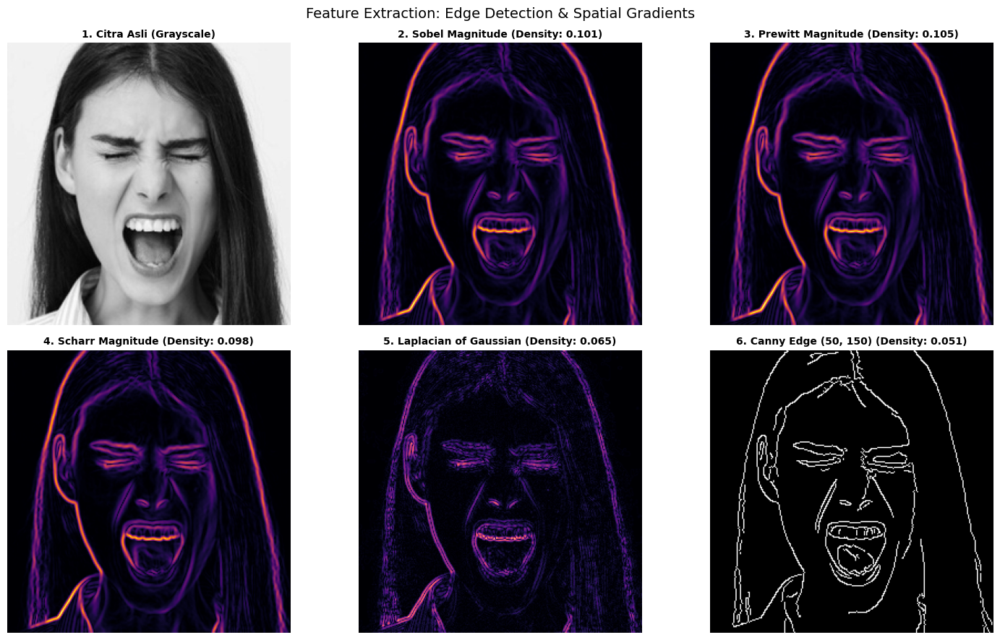

Kepadatan Tepi (Edge Densities):
 - Sobel     : 10.10% piksel tepi
 - Prewitt   : 10.47% piksel tepi
 - Scharr    : 9.84% piksel tepi
 - Laplacian : 6.47% piksel tepi
 - Canny     : 5.11% piksel tepi


In [71]:
# Eksekusi visualisasi perbandingan deteksi tepi dan peta gradien
edge_results = visualize_edge_features(
    sample_image,
    low_thresh=50,
    high_thresh=150,
    blur_ksize=3,
    show=True
)

print("Kepadatan Tepi (Edge Densities):")
for k, v in edge_results["edge_densities"].items():
    print(f" - {k.capitalize():10s}: {v*100:.2f}% piksel tepi")

---
## Section 14: Corner & Keypoint Detection

### Konsep Dasar & Definisi
Titik sudut (*corner*) dan titik kunci (*keypoint*) adalah lokasi citra dua dimensi yang memiliki variasi intensitas signifikan ke segala arah. Fitur ini sangat berguna untuk pelacakan objek, penyelarasan citra, dan pengenalan wajah:
- **Harris Corner Detector:** Membentuk matriks autokorelasi gradien (*structure tensor*) $M = \sum w(x,y) \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix}$, menghitung skor respons $R = \det(M) - k \cdot (\text{trace}(M))^2$.
- **Shi-Tomasi (*Good Features to Track*):** Menyederhanakan kriteria Harris dengan menggunakan nilai eigen terkecil: $R = \min(\lambda_1, \lambda_2)$. Jika kedua nilai eigen besar, titik tersebut dipastikan adalah sudut tajam.
- **FAST (*Features from Accelerated Segment Test*):** Menguji lingkaran 16 piksel di sekeliling calon sudut. Jika terdapat $N$ piksel berurutan yang jauh lebih terang atau lebih gelap dari piksel pusat, sudut terdeteksi secara instan.
- **SIFT (*Scale-Invariant Feature Transform*):** Detektor invarian skala menggunakan piramida *Difference of Gaussians* (DoG) dan menghasilkan deskriptor 128 dimensi berdasarkan histogram gradien orientasi lokal.
- **ORB (*Oriented FAST and Rotated BRIEF*):** Alternatif sumber terbuka yang cepat dan efisien, menggabungkan detektor FAST dengan deskriptor biner terotasi (32 bytes per keypoint).

### Kaitan dengan Preprocessing Part 1
Detektor SIFT dan Harris memanfaatkan piramida citra multi-skala (Section 10) serta penyesuaian kontras (Section 5) untuk memastikan kestabilan deteksi pada berbagai kondisi pencahayaan.

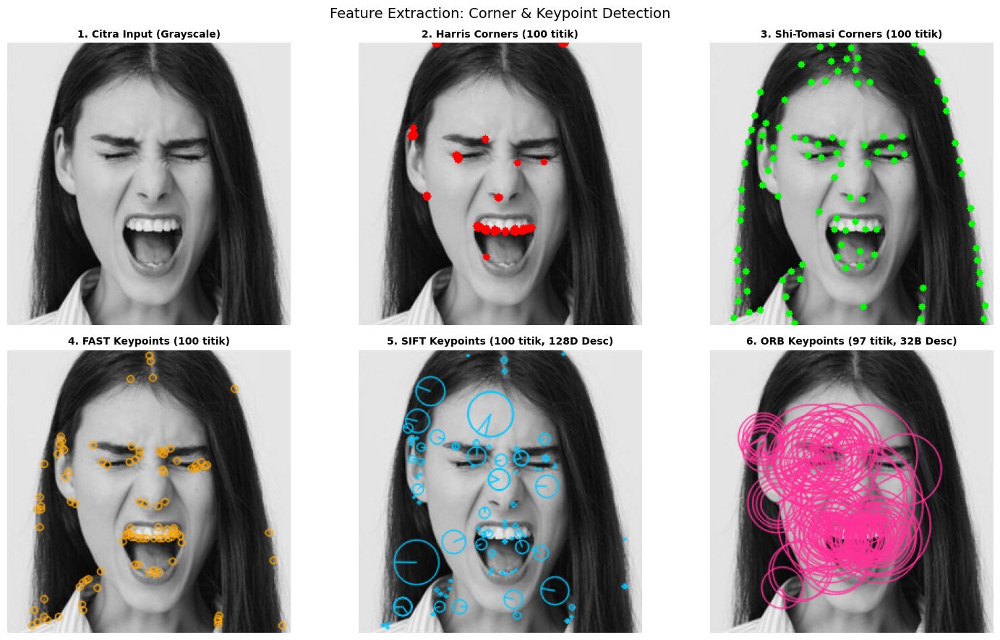

Jumlah Keypoint Terdeteksi:
 - Harris      : 100 titik jangkar
 - Shi_tomasi  : 100 titik jangkar
 - Fast        : 100 titik jangkar
 - Sift        : 100 titik jangkar
 - Orb         : 97 titik jangkar


In [72]:
# Eksekusi visualisasi deteksi titik sudut dan keypoint lokal
kp_results = visualize_keypoint_features(
    sample_image,
    max_corners=100,
    show=True
)

print("Jumlah Keypoint Terdeteksi:")
for method, count in kp_results["counts"].items():
    print(f" - {method.capitalize():12s}: {count} titik jangkar")

---
## Section 15: Tekstur (GLCM, LBP, & Gabor Filter Bank)

### Konsep Dasar & Definisi
Fitur tekstur mendeskripsikan variasi spasial dan keteraturan mikro pada intensitas piksel permukaan objek:
- **GLCM (*Gray-Level Co-occurrence Matrix*):** Memetakan probabilitas $P(i, j | d, \theta)$ bahwa piksel berintensitas $i$ bersebelahan dengan piksel $j$ pada jarak $d$ dan arah $\theta$. Parameter Haralick yang diekstrak meliputi:
  - *Contrast:* Mengukur variasi lokal intensitas (tinggi pada area bertekstur kasar).
  - *Homogeneity:* Mengukur kedekatan distribusi elemen ke diagonal matriks (tinggi pada area seragam).
  - *Energy (ASM):* Mengukur keteraturan tekstur kuadratik.
  - *Correlation:* Mengukur ketergantungan linier intensitas piksel tetangga.
- **LBP (*Local Binary Patterns*):** Mengomparasi piksel pusat dengan $P$ tetangga pada radius $R$, membentuk byte biner lokal. Pola seragam (*uniform patterns*) sangat tangguh untuk membedakan tekstur kulit wajah dan ekspresi emosi.
- **Gabor Filter Bank:** Filter linier yang memodulasi gelombang sinusoidal dengan fungsi Gaussian pada frekuensi $\lambda$ dan sudut $\theta$. Meniru karakteristik reseptif sistem visual manusia dalam mengenali orientasi tekstur.

### Kaitan dengan Preprocessing Part 1
Analisis GLCM dan LBP dibangun di atas normalisasi intensitas (Section 11) dan kuantisasi tingkat keabuan terkelola agar representasi tekstur tidak terdistorsi oleh perbedaan pencahayaan global.

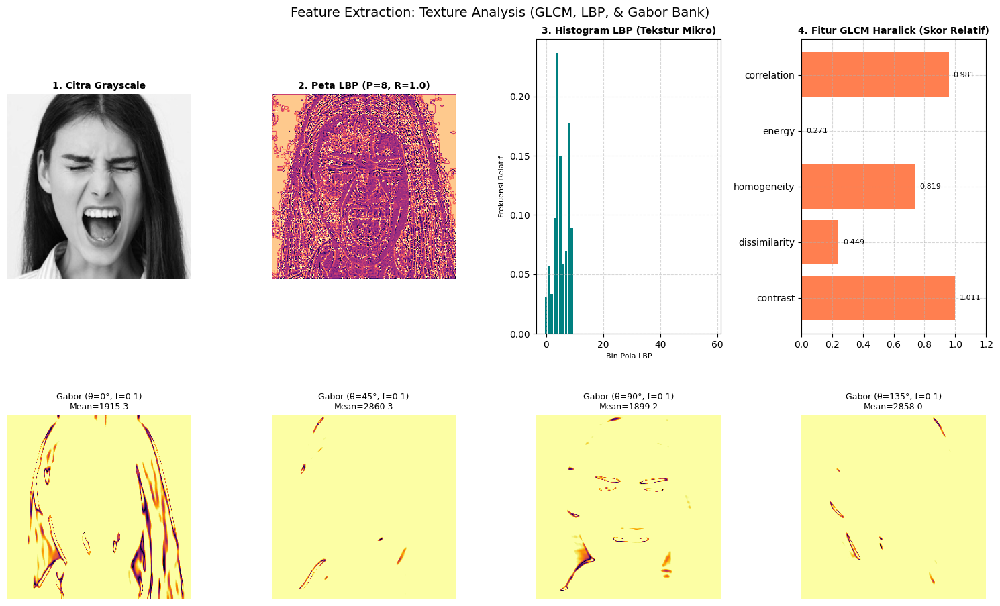

Fitur Tekstur Haralick (GLCM):
 - Contrast       : 1.0113
 - Dissimilarity  : 0.4487
 - Homogeneity    : 0.8189
 - Energy         : 0.2708
 - Correlation    : 0.9808
Dimensi Vektor Fitur LBP: 59 bins
Dimensi Vektor Fitur Gabor: 16 nilai (Mean & Std)


In [73]:
# Eksekusi visualisasi analisis tekstur komprehensif
texture_results = visualize_texture_features(
    sample_image,
    lbp_points=8,
    lbp_radius=1.0,
    show=True
)

print("Fitur Tekstur Haralick (GLCM):")
for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
    print(f" - {prop.capitalize():15s}: {texture_results['glcm_props'][prop]:.4f}")
print(f"Dimensi Vektor Fitur LBP: {len(texture_results['lbp_hist'])} bins")
print(f"Dimensi Vektor Fitur Gabor: {len(texture_results['gabor_features'])} nilai (Mean & Std)")

---
## Section 16: Warna (Histograms, Color Moments, & Palet Dominan)

### Konsep Dasar & Formulasi Matematis
Informasi warna menyediakan deskriptor global yang invarian terhadap translasi dan rotasi citra:
- **Color Histograms:** Distribusi frekuensi nilai piksel per kanal secara independen (1D RGB/HSV) maupun gabungan 2D (*Hue-Saturation*) untuk mengisolasi informasi kromatik murni dari intensitas cahaya.
- **Color Moments:** Momen statistik distribusi probabilitas warna pada setiap kanal:
  - *Momen ke-1 (Mean / Nilai Rata-rata):* $\mu_k = \frac{1}{N} \sum_{i=1}^N p_{i, k}$
  - *Momen ke-2 (Standard Deviation / Sebaran Warna):* $\sigma_k = \sqrt{\frac{1}{N} \sum_{i=1}^N (p_{i, k} - \mu_k)^2}$
  - *Momen ke-3 (Skewness / Kemiringan Distribusi):* $s_k = \left( \frac{1}{N} \sum_{i=1}^N (p_{i, k} - \mu_k)^3 \right)^{1/3}$
- **Dominant Colors (K-Means Clustering):** Mengelompokkan piksel RGB ke dalam $K$ klaster warna utama untuk mengekstrak palet warna khas objek beserta persentase kontribusinya.

### Kaitan dengan Preprocessing Part 1
Pemanfaatan ruang warna **HSV dan CIE LAB** secara langsung melanjutkan eksplorasi Section 1, memisahkan komponen luminans ($L$, $V$) dari krominans ($H, S$, $a, b$) agar fitur warna tahan terhadap variasi bayangan.

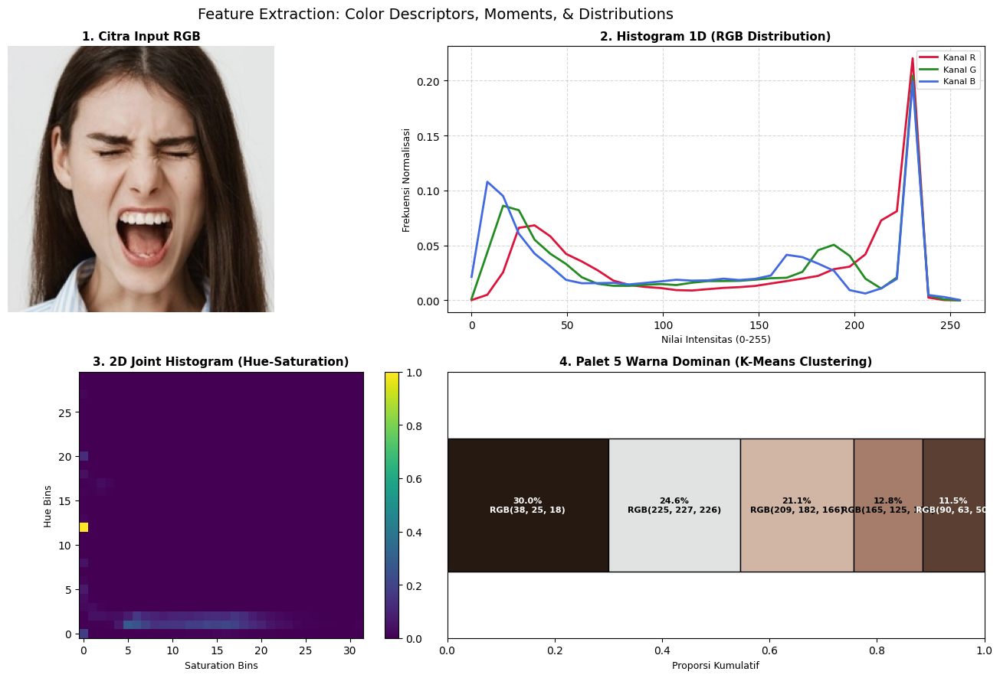

Momen Warna (Mean, Std, Skewness) pada Ruang HSV:
 - Kanal H: Mean=25.42, Std=30.50, Skewness=37.83
 - Kanal S: Mean=77.89, Std=57.30, Skewness=30.16
 - Kanal V: Mean=143.50, Std=80.87, Skewness=-54.80
Total Dimensi Vektor Warna Terpadu: 27 fitur


In [74]:
# Eksekusi visualisasi histogram warna, momen statistik, dan klasterisasi warna dominan
color_results = visualize_color_features(
    sample_image,
    n_dominant=5,
    show=True
)

print("Momen Warna (Mean, Std, Skewness) pada Ruang HSV:")
for ch, vals in color_results["moments"]["hsv"].items():
    print(f" - Kanal {ch}: Mean={vals['mean']:.2f}, Std={vals['std']:.2f}, Skewness={vals['skewness']:.2f}")
print(f"Total Dimensi Vektor Warna Terpadu: {len(color_results['color_vector'])} fitur")

---
## Section 17: Shape & Geometry (Kontur, Hu Moments, Hough, & HOG)

### Konsep Dasar & Formulasi Matematis
Fitur bentuk mendeskripsikan geometri eksternal objek yang membedakan siluet dan postur:
- **Deskriptor Kontur Geometris:** Mengukur properti spasial batas objek utama:
  - *Circularity (Compactness):* $C = \frac{4\pi \cdot \text{Area}}{\text{Perimeter}^2}$ ($1.0$ untuk lingkaran sempurna).
  - *Solidity:* Rasio antara luas kontur terhadap luas *Convex Hull* (kulit cembung luar): $\text{Solidity} = \frac{\text{Area}}{\text{ConvexHull Area}}$.
  - *Aspect Ratio & Extent:* Rasio lebar/tinggi dan rasio luas kontur terhadap luas *bounding box*.
- **Hu Invariant Moments:** 7 kombinasi momen sentral ternormalisasi yang dikembangkan oleh Ming-Kuei Hu (1962). Nilai ini **invarian terhadap translasi, penskalaan, dan rotasi** objek.
- **Hough Transform:** Memetakan ruang citra ke ruang parameter akumulator untuk mendeteksi garis lurus struktural (*Probabilistic Hough Lines*) dan kurva lingkaran (*Hough Circles*).
- **HOG (*Histogram of Oriented Gradients*):** Menghitung orientasi gradien piksel lokal pada sel spasial $16 \times 16$, menghasilkan vektor representasi bentuk yang sangat kuat untuk deteksi wajah dan figur manusia.

### Kaitan dengan Preprocessing Part 1
Ekstraksi bentuk bergantung langsung pada hasil **Binarisasi Otsu (Section 8)** dan pembersihan rongga biner menggunakan **Morfologi Closing (Section 6)** agar kontur luar objek tidak terputus.

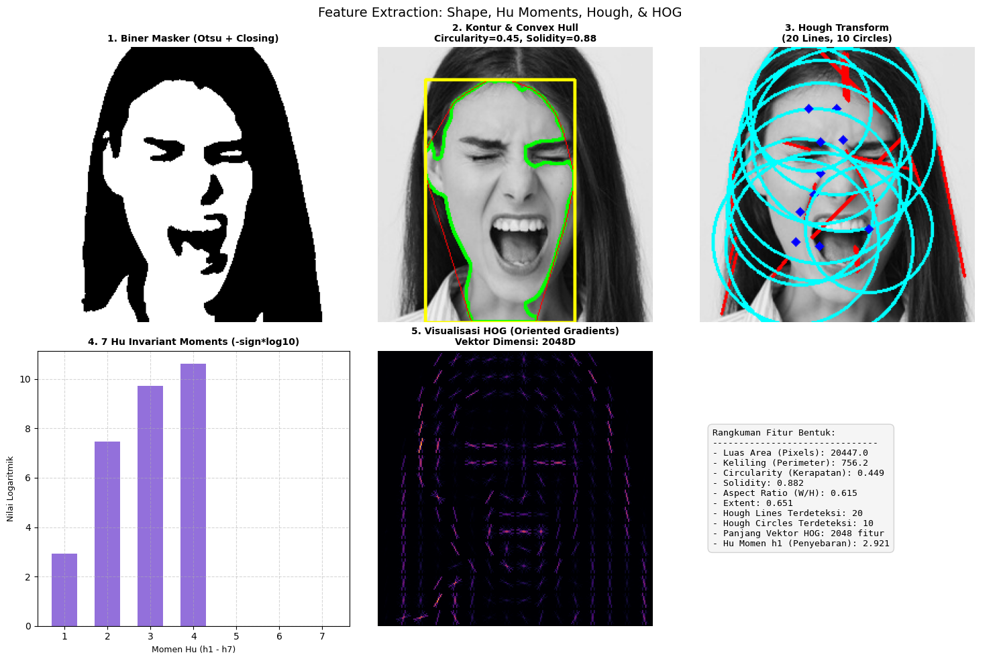

Deskriptor Geometris Kontur:
 - Luas Area: 20447.0 px | Keliling: 756.2 px
 - Circularity: 0.449 | Solidity: 0.882 | Aspect Ratio: 0.615
7 Invariant Hu Moments (-sign * log10): [ 2.921  7.459  9.728 10.609  0.     0.     0.   ]
Dimensi Vektor HOG: 2048 fitur gradien


In [75]:
# Eksekusi visualisasi analisis bentuk, kontur, Hough, dan HOG
shape_results = visualize_shape_features(
    sample_image,
    show=True
)

cp = shape_results["contour_props"]
print("Deskriptor Geometris Kontur:")
print(f" - Luas Area: {cp['area']:.1f} px | Keliling: {cp['perimeter']:.1f} px")
print(f" - Circularity: {cp['circularity']:.3f} | Solidity: {cp['solidity']:.3f} | Aspect Ratio: {cp['aspect_ratio']:.3f}")
print(f"7 Invariant Hu Moments (-sign * log10): {np.round(shape_results['hu_moments_log'], 3)}")
print(f"Dimensi Vektor HOG: {len(shape_results['hog_vector'])} fitur gradien")

---
## Section 18: Sintesis Vektor Fitur Terpadu (Unified Feature Vector)

### Konsep Pembentukan Vektor Fitur untuk Pengenalan Pola
Dalam arsitektur sistem Pengenalan Pola (*Pattern Recognition Pipeline*), seluruh deskriptor yang diekstrak dari berbagai modalitas (Tepi, Titik Kunci, Tekstur, Warna, dan Bentuk) digabungkan (*concatenated*) menjadi satu **Vektor Fitur Karakteristik 1D ($X \in \mathbb{R}^D$)**.

Vektor gabungan ini kemudian siap ditransformasikan melalui reduksi dimensi (misal PCA / LDA) atau diinputkan langsung ke algoritma pengklasifikasi (*Classifier*) seperti **Support Vector Machine (SVM), k-Nearest Neighbors (k-NN), Random Forest, atau Multi-Layer Perceptron (MLP)**.

In [76]:
# Gabungkan fitur tekstur (LBP, Gabor), warna (Moments), dan bentuk (Hu, HOG) ke dalam satu vektor
glcm_vec = np.array([texture_results['glcm_props'][p] for p in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']], dtype=np.float32)
lbp_vec = texture_results['lbp_hist'].astype(np.float32)
gabor_vec = texture_results['gabor_features'].astype(np.float32)
color_vec = color_results['color_vector'].astype(np.float32)
hu_vec = shape_results['hu_moments_log'].astype(np.float32)
hog_vec = shape_results['hog_vector'].astype(np.float32)

# Agregasi vektor fitur gabungan
unified_feature_vector = np.concatenate([
    glcm_vec,
    lbp_vec,
    gabor_vec,
    color_vec,
    hu_vec,
    hog_vec
])

print("=== RANGKUMAN VEKTOR FITUR CITRA EKSPERIMEN ===")
print(f"1. Fitur GLCM Haralick       : {len(glcm_vec):4d} dimensi")
print(f"2. Fitur LBP Histogram       : {len(lbp_vec):4d} dimensi")
print(f"3. Fitur Gabor Filter Bank   : {len(gabor_vec):4d} dimensi")
print(f"4. Fitur Momen Warna (RGB/H/L: {len(color_vec):4d} dimensi")
print(f"5. Fitur 7 Hu Moments Invar  : {len(hu_vec):4d} dimensi")
print(f"6. Fitur HOG Gradients       : {len(hog_vec):4d} dimensi")
print("--------------------------------------------------")
print(f"TOTAL DIMENSI VEKTOR FITUR (D) : {len(unified_feature_vector)} fitur numerik")
print(f"Tipe Data Vektor Fitur        : {unified_feature_vector.dtype}")
print(f"Nilai Vektor (Min, Max, Mean) : ({unified_feature_vector.min():.3f}, {unified_feature_vector.max():.3f}, {unified_feature_vector.mean():.3f})")

=== RANGKUMAN VEKTOR FITUR CITRA EKSPERIMEN ===
1. Fitur GLCM Haralick       :    5 dimensi
2. Fitur LBP Histogram       :   59 dimensi
3. Fitur Gabor Filter Bank   :   16 dimensi
4. Fitur Momen Warna (RGB/H/L:   27 dimensi
5. Fitur 7 Hu Moments Invar  :    7 dimensi
6. Fitur HOG Gradients       : 2048 dimensi
--------------------------------------------------
TOTAL DIMENSI VEKTOR FITUR (D) : 2162 fitur numerik
Tipe Data Vektor Fitur        : float32
Nilai Vektor (Min, Max, Mean) : (-54.821, 2860.263, 8.348)


---
## Kesimpulan dan Refleksi Hasil Eksperimen Terpadu

Berdasarkan seluruh eksplorasi pada proyek **Image Preprocessing Playground & Feature Extraction Playground** ini, dapat dirangkum beberapa wawasan kunci bagi mata kuliah Pengenalan Pola:

1. **Sinergi Preprocessing dan Feature Extraction:**
   - Kualitas fitur sangat ditentukan oleh kebersihan citra hasil pra-pengolahan. Noise yang dibiarkan akan memicu deteksi tepi palsu (*Sobel/Canny*) dan merusak nilai orientasi gradien (*HOG*).
   - Operasi binarisasi dan morfologi menjadi fondasi mutlak bagi ekstraksi bentuk dan momen geometris (*Hu Moments, Contour analysis*).

2. **Karakteristik 5 Kelompok Fitur:**
   - **Edge Detection:** Menangkap batas-batas struktural transisi intensitas tajam.
   - **Corner & Keypoint:** Titik-titik referensi spasial invarian yang unik untuk pencocokan (*matching*).
   - **Tekstur (GLCM, LBP, Gabor):** Sangat efektif membedakan karakteristik mikro permukaan wajah/kulit dan ekspresi.
   - **Warna (Color Moments & Histograms):** Memberikan invariansi rotasi dan sudut pandang, terutama pada ruang warna terpisah seperti HSV dan CIE LAB.
   - **Shape (Hu Moments & HOG):** Memberikan deskripsi bentuk global yang tangguh terhadap rotasi, translasi, dan skala.

3. **Kesiapan Menuju Klasifikasi:**
   - Dengan teragregasinya seluruh fitur ke dalam satu vektor numerik 1D (`unified_feature_vector`), citra kini telah bertransformasi dari kumpulan matriks piksel mentah menjadi representasi berdimensi terkelola yang siap diproses oleh algoritma pembelajaran mesin (*Machine Learning Classifier*).